In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, classification_report, accuracy_score

In [ ]:
SEED = 42

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
models = {
    "MLE - UR": LogisticRegression(penalty=None, solver="lbfgs", max_iter=10000, random_state=SEED),
    "MAP - L2": LogisticRegression(penalty="l2", C=1.0, solver="lbfgs", max_iter=10000, random_state=SEED),
    "MAP - L1": LogisticRegression(penalty="l1", C=1.0, solver="saga", max_iter=10000, random_state=SEED),
    "MAP - L1 Stronger": LogisticRegression(penalty="l1", C=0.1, solver="saga", max_iter=10000, random_state=SEED),
}

In [ ]:
results = []
coefficients = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    loss = log_loss(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Log Loss": loss,
        "Zero-weights (sparsity)": np.sum(model.coef_ == 0)
    })

    coefficients[name] = model.coef_[0]

--- Performance Comparison ---
            Model  Accuracy     Log Loss  Zero-weights (sparsity)
         MLE - UR  0.982456 6.323448e-01                        0
         MAP - L2  1.000000 2.220446e-16                        0
         MAP - L1  1.000000 2.220446e-16                       13
MAP - L1 Stronger  0.982456 6.323448e-01                       21


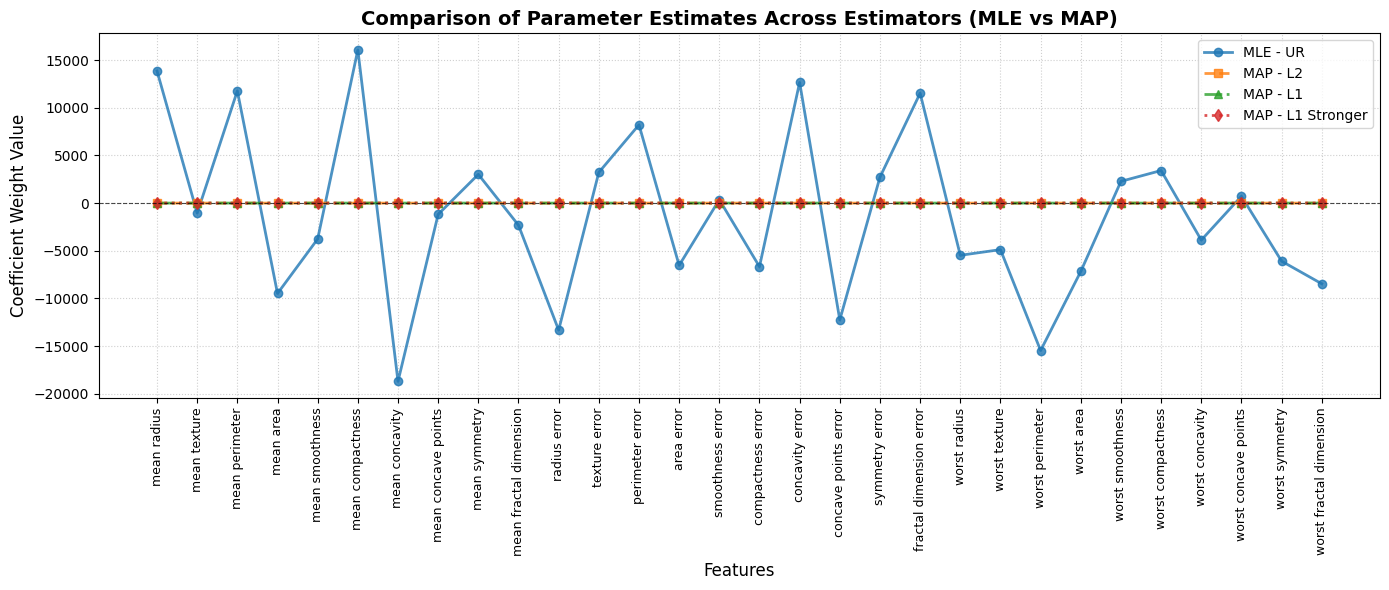

In [ ]:
results_df = pd.DataFrame(results)
coef_df = pd.DataFrame(coefficients, index=data.feature_names)

print("--- Performance Comparison ---")
print(results_df.to_string(index=False))

plt.figure(figsize=(14, 6))
feature_indices = np.arange(len(data.feature_names))

markers = ['o', 's', '^', 'd']
linestyles = ['-', '--', '-.', ':']

for (col, marker, ls) in zip(coef_df.columns, markers, linestyles):
    plt.plot(feature_indices, coef_df[col], label=col, marker=marker, linestyle=ls, alpha=0.8, linewidth=2)

plt.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
plt.xticks(feature_indices, data.feature_names, rotation=90, fontsize=9)
plt.ylabel("Coefficient Weight Value", fontsize=12)
plt.xlabel("Features", fontsize=12)
plt.title("Comparison of Parameter Estimates Across Estimators (MLE vs MAP)", fontsize=14, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10, loc='upper right')
plt.tight_layout()
plt.savefig("coef_line_graph.png", dpi=300)
plt.show()